**Exploratory Data Analysis**

In [131]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Note**
The data is not saved within this repository. You will need to import it into this working directory. After that, run the cell below. 

In [132]:
df = pd.read_csv('ENB2012_data.csv')
df.head(4)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


**Note** The dataframe lacks the descirptive titles for each feature, so the below cell renames them, while also adding additional information. 

In [133]:
df.rename(columns={'X1':'Relative Compactness',
                    'X2':'Surface Area',
                    'X3':'Wall Area (m^2)',
                    'X4':'Roof Area (m^2)',
                    'X5':'Overall Height (m)',
                    'X6':'Orientation',
                    'X7':'Glazing Area',
                    'X8':'Glazing Area Distribution',
                    'Y1':'Heating Load',
                    'Y2':'Cooling Load'}, 
                    inplace=True)

In [134]:
df.head(4)

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


In [135]:
#There are 528 rows of null data in the dataset. We will drop them since they are not many and we have enough data to work with.
df.isnull().sum()

Relative Compactness         528
Surface Area                 528
Wall Area (m^2)              528
Roof Area (m^2)              528
Overall Height (m)           528
Orientation                  528
Glazing Area                 528
Glazing Area Distribution    528
Heating Load                 528
Cooling Load                 528
dtype: int64

These 528 rows are rows of data tha follow the 768th row of actual data. These rows have nothing in them, and accoring to the introductory paper there are only 768 rows of data. This makes them safe to remove from our dataset.

In [136]:
#removed null values
df.dropna(inplace=True)
df.isnull().sum()

Relative Compactness         0
Surface Area                 0
Wall Area (m^2)              0
Roof Area (m^2)              0
Overall Height (m)           0
Orientation                  0
Glazing Area                 0
Glazing Area Distribution    0
Heating Load                 0
Cooling Load                 0
dtype: int64

In [137]:
#Check for duplicates
df.duplicated().sum()

0

In [138]:
df.nunique()

Relative Compactness          12
Surface Area                  12
Wall Area (m^2)                7
Roof Area (m^2)                4
Overall Height (m)             2
Orientation                    4
Glazing Area                   4
Glazing Area Distribution      6
Heating Load                 586
Cooling Load                 636
dtype: int64

In [139]:
df[['Orientation', 'Glazing Area Distribution']] = df[['Orientation', 'Glazing Area Distribution']].astype('category')

In [ ]:
df.describe(include='number').style.format("{:.2f}")

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Glazing Area,Heating Load,Cooling Load
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.76,671.71,318.50,176.60,5.25,0.23,22.31,24.59
std,0.11,88.09,43.63,45.17,1.75,0.13,10.09,9.51
min,0.62,514.50,245.00,110.25,3.50,0.00,6.01,10.90
25%,0.68,606.38,294.00,140.88,3.50,0.10,12.99,15.62
50%,0.75,673.75,318.50,183.75,5.25,0.25,18.95,22.08
75%,0.83,741.12,343.00,220.50,7.00,0.40,31.67,33.13
max,0.98,808.50,416.50,220.50,7.00,0.40,43.10,48.03


In [141]:
df.to_csv('ENB2012_data_cleaned.csv', index=False)

In [142]:
df.describe(include='category').style.format("{:.2f}") #all Data are numeric and there are no missing values.

,Orientation,Glazing Area Distribution
count,768.00,768.00
unique,4.00,6.00
top,2.00,1.00
freq,192.00,144.00


Text(0, 0.5, 'Frequency')

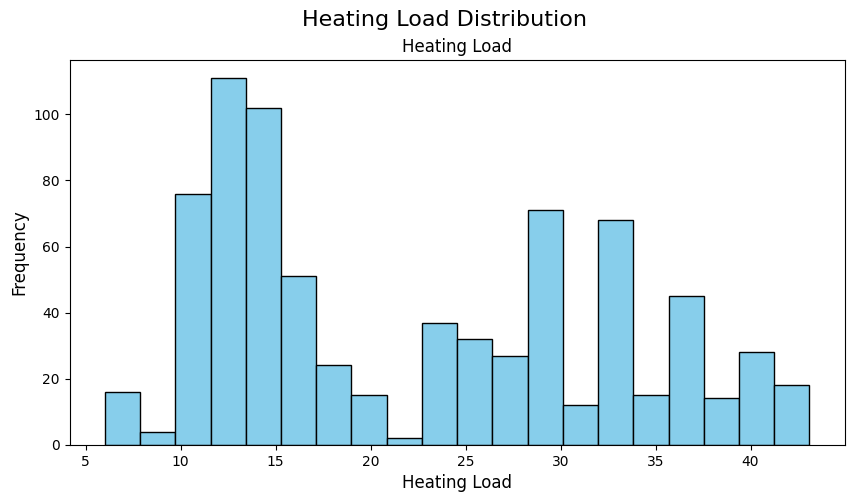

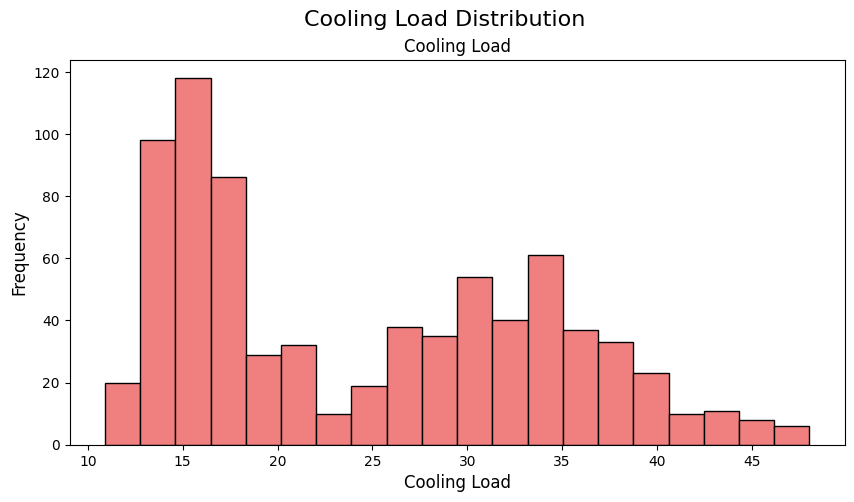

In [143]:
#Histograms for Heating Load and Cooling Load
ax = df[['Heating Load']].hist(bins=20, figsize=(10, 5), grid=False, color='skyblue', edgecolor='black')
plt.suptitle('Heating Load Distribution', fontsize=16)
plt.xlabel('Heating Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

ax = df[['Cooling Load']].hist(bins=20, figsize=(10, 5), grid=False, color='lightcoral', edgecolor='black')
plt.suptitle('Cooling Load Distribution', fontsize=16)
plt.xlabel('Cooling Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

Both targets have mild positive skewness, with means exceeding their medians. The histograms show multiple peaks or clusters.

In [144]:
loads = df[['Heating Load', 'Cooling Load']]

summary = loads.agg(['mean', 'median', 'skew']).T
display(summary)

,mean,median,skew
Heating Load,22.307201,18.95,0.360449
Cooling Load,24.587760,22.08,0.395992


,Heating Load,Cooling Load
Heating Load,1.000000,0.975862
Cooling Load,0.975862,1.000000


,Heating Load,Cooling Load
Heating Load,1.000000,0.972689
Cooling Load,0.972689,1.000000


Share of low-heating designs also low-cooling: 87.0%


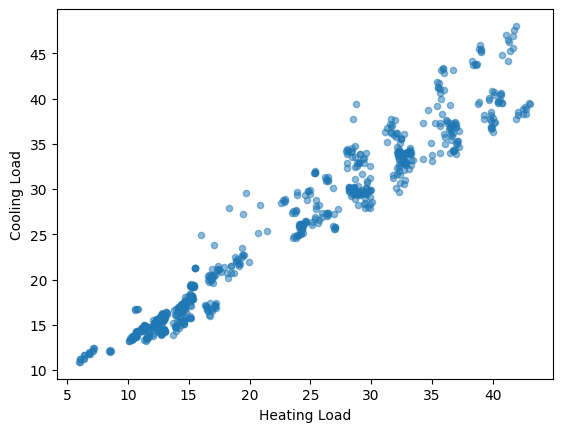

In [145]:
heating = "Heating Load"
cooling = "Cooling Load"

display(df[[heating, cooling]].corr(method="pearson"))
display(df[[heating, cooling]].corr(method="spearman"))

ax = df.plot.scatter(x=heating, y=cooling, alpha=0.5)

low_heating = df[heating] <= df[heating].quantile(0.25)
low_cooling = df[cooling] <= df[cooling].quantile(0.25)

print(
    "Share of low-heating designs also low-cooling:",
    f"{low_cooling[low_heating].mean():.1%}"
)

Heating and cooling loads are strongly positively associated (Pearson r = 0.976; Spearman ρ = 0.973). Among designs in the lowest heating-load quartile, 87.0% also fall in the lowest cooling-load quartile.

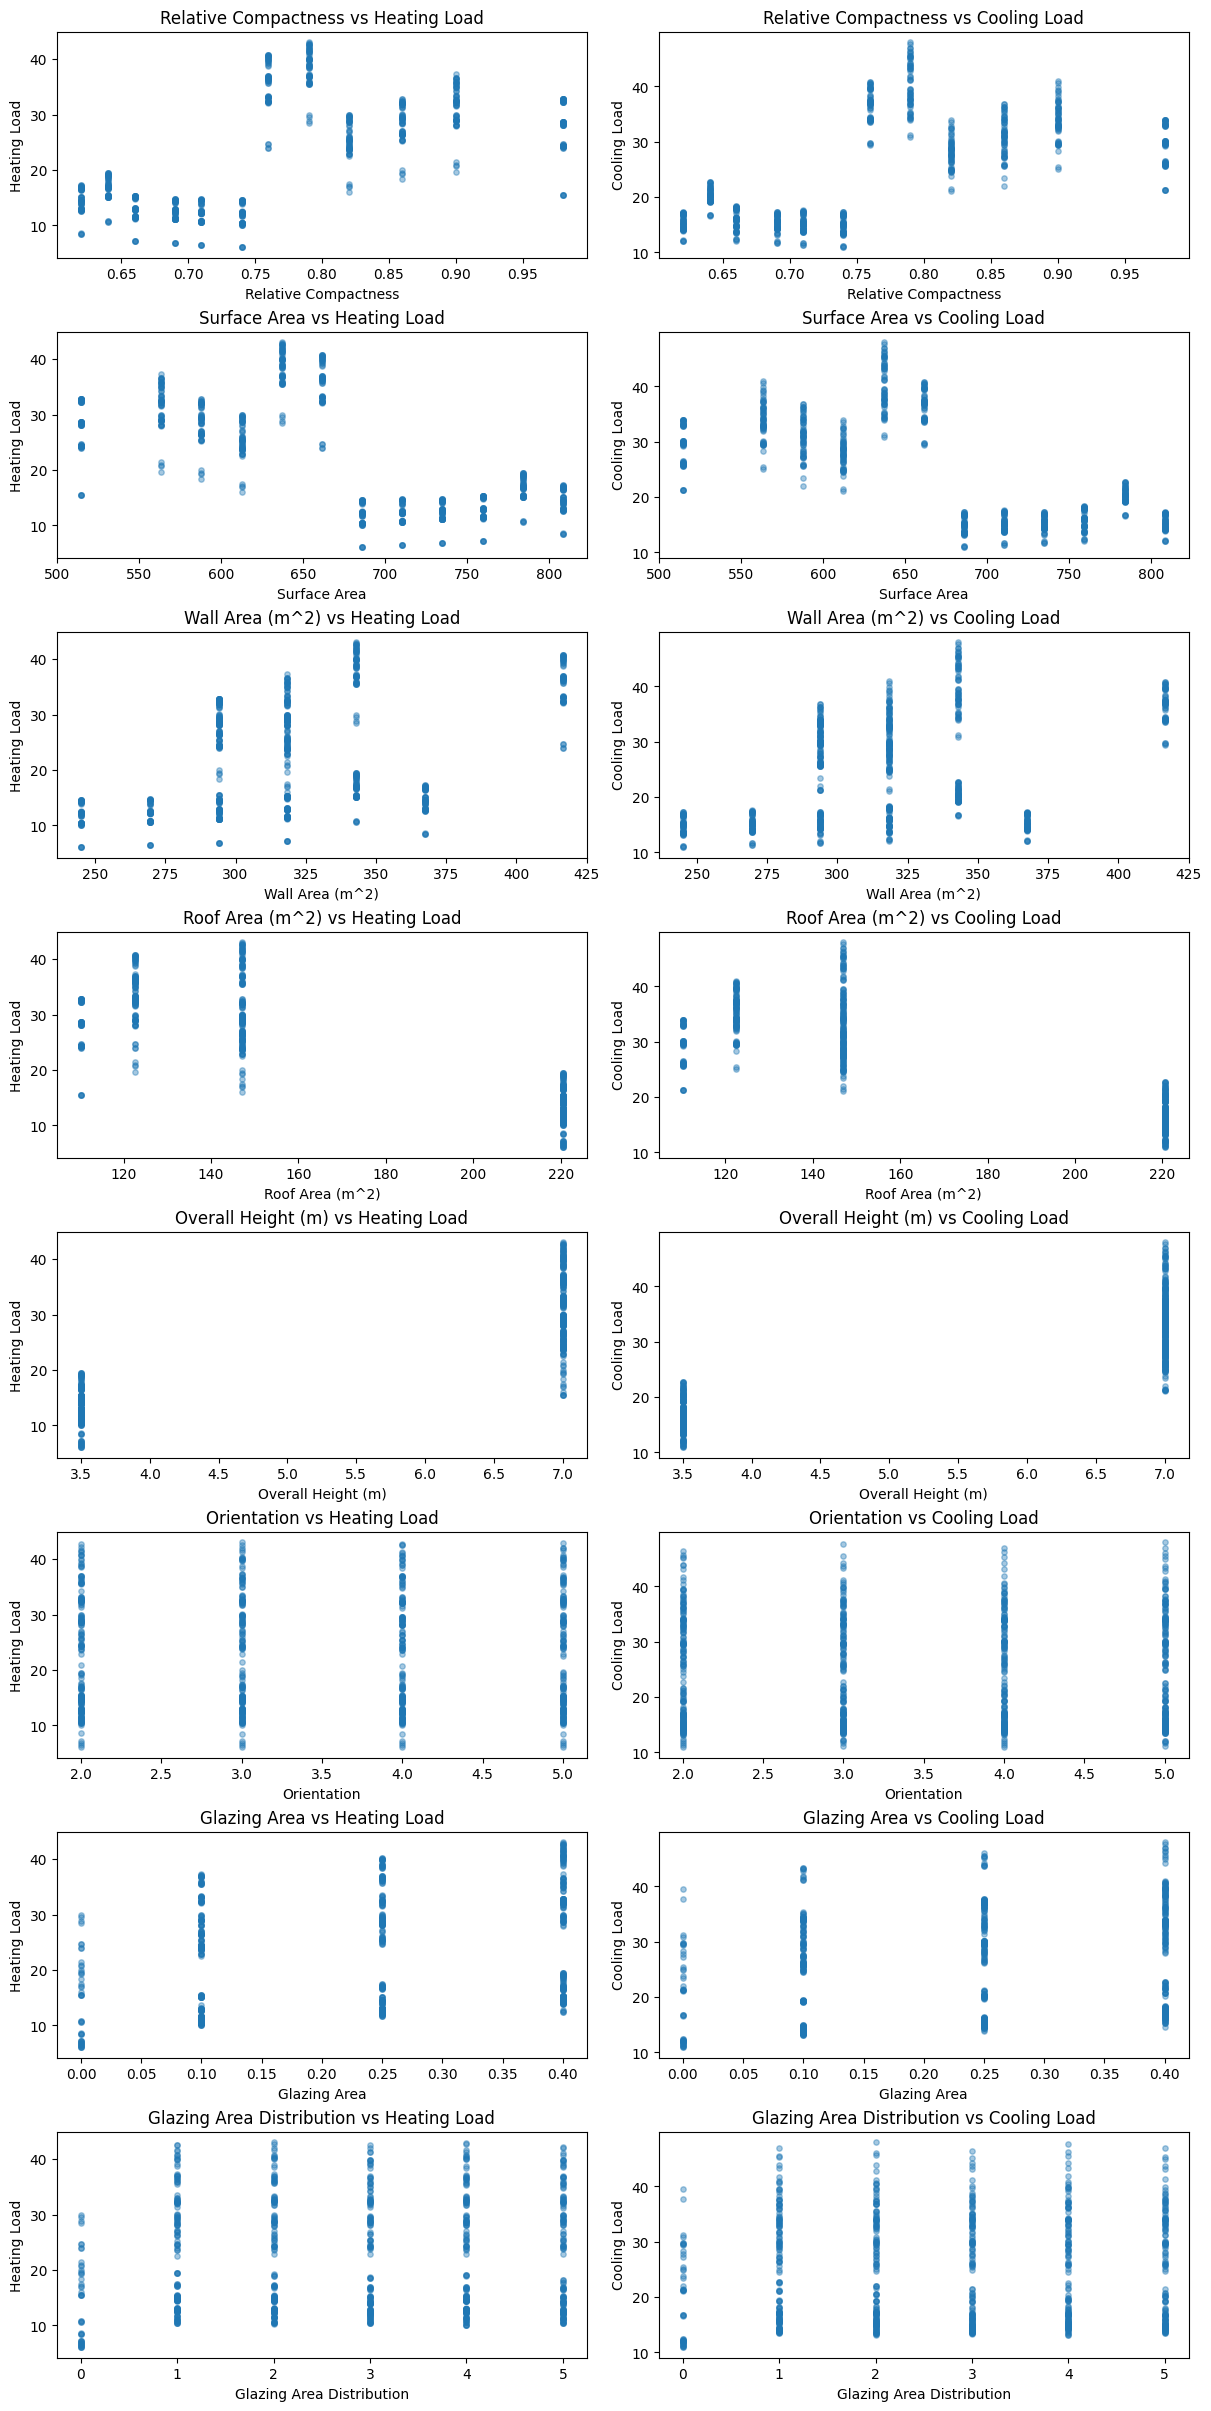

In [146]:
features = ['Relative Compactness',
                    'Surface Area',
                    'Wall Area (m^2)',
                    'Roof Area (m^2)',
                    'Overall Height (m)',
                    'Orientation',
                    'Glazing Area',
                    'Glazing Area Distribution'
]
targets = ['Heating Load', 'Cooling Load']

fig, axes = plt.subplots(
    len(features), 2,
    figsize=(12, 3 * len(features)),
    constrained_layout=True
)

for row, feature in enumerate(features):
    for col, target in enumerate(targets):
        ax = axes[row, col]
        ax.scatter(df[feature], df[target], alpha=0.4, s=15)
        ax.set_xlabel(feature)
        ax.set_ylabel(target)
        ax.set_title(f'{feature} vs {target}')

plt.show()

Heating and cooling loads show similar relationships with the building geometry features. Relative compactness and wall area have positive associations with both targets, while surface area and roof area have negative associations. However, the plots contain distinct clusters and nonlinear patterns, suggesting that individual features do not fully explain energy demand and should be considered collectively.

In [147]:
#Correlation matrix for all features and targets
for feature in features:
    if feature in ['Orientation', 'Glazing Area Distribution']:
        continue
    print(f'Spearman Correlation between {feature} and {targets[0]}: {df[[feature,targets[0]]].corr(method="spearman").iloc[0,1]:.2f}')
    print(f'Spearman Correlation between {feature} and {targets[1]}: {df[[feature,targets[1]]].corr(method="spearman").iloc[0,1]:.2f}\n')

Spearman Correlation between Relative Compactness and Heating Load: 0.62
Spearman Correlation between Relative Compactness and Cooling Load: 0.65

Spearman Correlation between Surface Area and Heating Load: -0.62
Spearman Correlation between Surface Area and Cooling Load: -0.65

Spearman Correlation between Wall Area (m^2) and Heating Load: 0.47
Spearman Correlation between Wall Area (m^2) and Cooling Load: 0.42

Spearman Correlation between Roof Area (m^2) and Heating Load: -0.80
Spearman Correlation between Roof Area (m^2) and Cooling Load: -0.80

Spearman Correlation between Overall Height (m) and Heating Load: 0.86
Spearman Correlation between Overall Height (m) and Cooling Load: 0.86

Spearman Correlation between Glazing Area and Heating Load: 0.32
Spearman Correlation between Glazing Area and Cooling Load: 0.29



Spearman correlation summarizes rank-based association without assuming a linear relationship.

# Delete this message

Data cleaning, descriptive summaries, target distributions, and initial feature-target analysis is complete. 

Whats left is categorical comparissons, predictor relationships, cluster exploration, and unusal-observation checks. Then we put togheter our final findings.

If time allows we then do feature and modeling.

# Building Design and Energy Needs
**Phase 4 · Modeling and Evaluation | Team Game Theory**

Predict heating and cooling loads from eight design features. To rerun, put the project CSV beside this notebook and select **Run All**. [UCI dataset](https://archive.ics.uci.edu/dataset/242/energy+efficiency)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

SEED = 42
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | NumPy {np.__version__}")

scikit-learn 1.8.0 | pandas 2.2.3 | NumPy 2.3.5


## 1. Load the Phase 3 features and targets

In [2]:
# Prefer the cleaned Phase 3 export when it is available.
filenames = ["ENB2012_data_cleaned.csv", "ENB2012_data.csv", "ENB2012_data (1).csv"]
data_path = next((Path(name) for name in filenames if Path(name).is_file()), None)
# For a different location, set data_path = Path("data/ENB2012_data.csv") here.
if data_path is None:
    raise FileNotFoundError("Place the Phase 3 export or original CSV beside the notebook, or set data_path.")

column_names = {
    "X1": "Relative Compactness",
    "X2": "Surface Area",
    "X3": "Wall Area (m^2)",
    "X4": "Roof Area (m^2)",
    "X5": "Overall Height (m)",
    "X6": "Orientation",
    "X7": "Glazing Area",
    "X8": "Glazing Area Distribution",
    "Y1": "Heating Load",
    "Y2": "Cooling Load",
}
raw = pd.read_csv(data_path).rename(columns=column_names)
data = raw[list(column_names.values())].dropna(how="all").apply(pd.to_numeric).reset_index(drop=True)
if data.isna().any().any():
    raise ValueError("A partially filled design row needs review before fitting.")

targets = ["Heating Load", "Cooling Load"]
X = data.drop(columns=targets)
y = data[targets]
shape_features = ["Relative Compactness", "Surface Area", "Wall Area (m^2)",
                  "Roof Area (m^2)", "Overall Height (m)"]
category_features = ["Orientation", "Glazing Area Distribution"]
numeric_features = shape_features + ["Glazing Area"]
groups = X.groupby(shape_features, sort=True).ngroup()

print(f"Input: {data_path.name}")
print(f"Complete designs: {len(data)} | Empty rows removed: {len(raw) - len(data)}")
print(f"Predictors: {X.shape[1]} | Targets: {len(targets)} | Base geometries: {groups.nunique()}")

Input: ENB2012_data (1).csv
Complete designs: 768 | Empty rows removed: 528
Predictors: 8 | Targets: 2 | Base geometries: 12


## 2. Split by building shape

Use nine shapes for training and validation. Reserve three unseen shapes (192 designs) for testing.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
cv = GroupKFold(n_splits=3)

assert set(train_groups).isdisjoint(test_groups)
for fit_idx, val_idx in cv.split(X_train, groups=train_groups):
    assert set(train_groups.iloc[fit_idx]).isdisjoint(train_groups.iloc[val_idx])

print(f"Development set: {len(X_train)} designs in {train_groups.nunique()} geometries")
print(f"Final test set:  {len(X_test)} designs in {test_groups.nunique()} geometries")

Development set: 576 designs in 9 geometries
Final test set:  192 designs in 3 geometries


## 3. Tune four model families

Compare KNN, Ridge, support vector regression (SVR), and Random Forest. Select the lowest mean absolute error (MAE) across three validation folds using 79 settings per target.

In [4]:
models = {
    "KNN": (
        KNeighborsRegressor(),
        {"model__n_neighbors": [3, 5, 9, 15, 25], "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
    ),
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    ),
    "RBF SVR": (
        SVR(kernel="rbf"),
        {"model__C": [1, 10, 100, 1000], "model__gamma": ["scale", 0.01, 0.1],
         "model__epsilon": [0.1, 0.5, 1.0]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=120, random_state=SEED),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [1, 3, 6],
         "model__max_features": [0.75, 1.0]},
    ),
}

In [5]:
fitted = {}
tuning_rows = []

for target in targets:
    for family, (estimator, param_grid) in models.items():
        numeric_step = "passthrough" if family == "Random Forest" else StandardScaler()
        preprocess = ColumnTransformer([
            ("numeric", numeric_step, numeric_features),
            ("categories", OneHotEncoder(handle_unknown="ignore"), category_features),
        ])
        pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
        search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="neg_mean_absolute_error",
                              refit=True, error_score="raise")
        search.fit(X_train, y_train[target], groups=train_groups)
        fitted[target, family] = search.best_estimator_

        best_settings = ", ".join(f"{key.removeprefix('model__')}={value}"
                                  for key, value in search.best_params_.items())
        tuning_rows.append({
            "Target": target, "Family": family,
            "Settings tried": len(search.cv_results_["params"]),
            "CV MAE": -search.best_score_,
            "Fold SD": search.cv_results_["std_test_score"][search.best_index_],
            "Best settings": best_settings,
        })

tuning = pd.DataFrame(tuning_rows)
winner_rows = tuning.groupby("Target", sort=False)["CV MAE"].idxmin()
selected = tuning.loc[winner_rows].set_index("Target")["Family"]
print("Selected from training folds")
for target in targets:
    print(f"{target}: {selected[target]}")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tuning.set_index(["Target", "Family"]).round(3))

Selected from training folds
Heating Load: RBF SVR
Cooling Load: RBF SVR


Settings tried  CV MAE  Fold SD  \
Target       Family                                           
Heating Load KNN                        20   3.764    1.864   
             Ridge                       5   3.648    0.782   
             RBF SVR                    36   3.306    1.515   
             Random Forest              18   4.962    2.690   
Cooling Load KNN                        20   3.731    1.505   
             Ridge                       5   3.776    1.072   
             RBF SVR                    36   3.026    1.468   
             Random Forest              18   4.566    2.439   

                                                                 Best settings  
Target       Family                                                             
Heating Load KNN                           n_neighbors=5, p=1, weights=uniform  
             Ridge                                                   alpha=100  
             RBF SVR                              C=1, epsilon=0.5, gamma=0.01  
             Random Forest  max_depth=4, max_features=0.75, min_samples_leaf=3  
Cooling Load KNN                          n_neighbors=25, p=1, weights=uniform  
             Ridge                                                   alpha=100  
             RBF SVR                              C=1, epsilon=1.0, gamma=0.01  
             Random Forest  max_depth=4, max_features=0.75, min_samples_leaf=3

## 4. Test results

Compare each tuned model with the training-mean baseline. Lower MAE and RMSE and higher R² indicate better predictions.

In [6]:
test_rows = []
predictions = {}

for target in targets:
    mean_model = DummyRegressor(strategy="mean").fit(X_train, y_train[target])
    test_models = {"Training mean": mean_model, **{family: fitted[target, family] for family in models}}
    for family, model in test_models.items():
        predicted = pd.Series(model.predict(X_test), index=X_test.index)
        predictions[target, family] = predicted
        actual = y_test[target]
        test_rows.append({
            "Target": target, "Family": family, "CV choice": "Yes" if family == selected[target] else "",
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R²": r2_score(actual, predicted),
        })

scores = pd.DataFrame(test_rows).set_index(["Target", "Family"])
display(scores.round(3))

CV choice    MAE   RMSE     R²
Target       Family                                      
Heating Load Training mean            8.268  8.878 -0.166
             KNN                      1.599  2.049  0.938
             Ridge                    2.464  2.754  0.888
             RBF SVR             Yes  3.235  3.367  0.832
             Random Forest            3.170  3.520  0.817
Cooling Load Training mean            8.555  9.093 -0.102
             KNN                      3.131  3.481  0.839
             Ridge                    3.527  4.133  0.772
             RBF SVR             Yes  3.890  4.394  0.743
             Random Forest            4.338  4.815  0.691

### Predicted versus simulated load

The dashed line marks a perfect prediction.

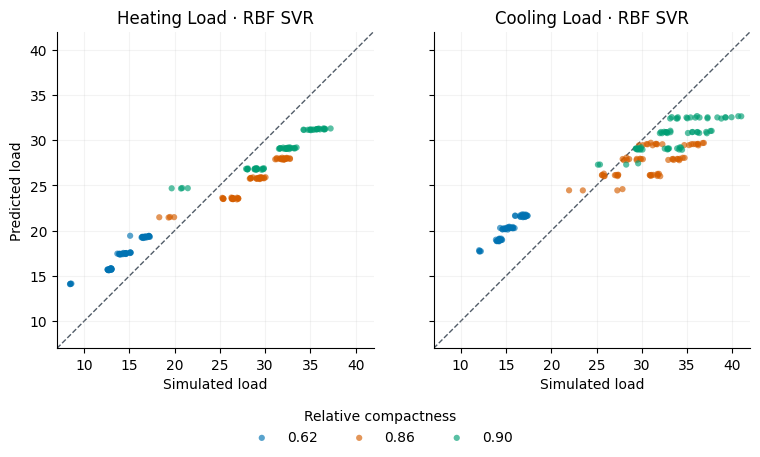

In [7]:
compactness = X_test["Relative Compactness"]
colors = ["#0072B2", "#D55E00", "#009E73"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.8), sharex=True, sharey=True)
chosen_values = [predictions[target, selected[target]].to_numpy() for target in targets]
all_values = np.concatenate([y_test.to_numpy().ravel(), *chosen_values])
limits = (np.floor(all_values.min()) - 1, np.ceil(all_values.max()) + 1)

for ax, target in zip(axes, targets):
    predicted = predictions[target, selected[target]]
    ax.plot(limits, limits, "--", color="#515C68", linewidth=1, zorder=1)
    for shape, color in zip(sorted(compactness.unique()), colors):
        rows = compactness == shape
        ax.scatter(y_test.loc[rows, target], predicted.loc[rows], label=f"{shape:.2f}",
                   s=20, alpha=0.65, color=color, edgecolors="none", zorder=2)
    ax.set(title=f"{target} · {selected[target]}", xlabel="Simulated load", xlim=limits, ylim=limits)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Predicted load")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Relative compactness", loc="lower center", ncol=3, frameon=False)
fig.subplots_adjust(bottom=0.22, wspace=0.12)
plt.show()

In [8]:
shape_errors = pd.DataFrame({"Relative compactness": compactness})
for target in targets:
    shape_errors[f"{target} MAE"] = (y_test[target] - predictions[target, selected[target]]).abs()
shape_summary = shape_errors.groupby("Relative compactness").mean()
shape_summary.insert(0, "Designs", shape_errors.groupby("Relative compactness").size())
display(shape_summary.round(3))

,Designs,Heating Load MAE,Cooling Load MAE
Relative compactness,,,
0.62,64,3.012,4.889
0.86,64,3.328,3.428
0.90,64,3.363,3.354


## 5. Feature importance

Shuffle geometry, glazing, or orientation separately. A larger increase in MAE means the model relied more on that group.

In [9]:
feature_groups = {
    "Geometry": shape_features,
    "Glazing": ["Glazing Area", "Glazing Area Distribution"],
    "Orientation": ["Orientation"],
}
rng = np.random.default_rng(SEED)
row_orders = [rng.permutation(len(X_test)) for _ in range(20)]
reliance = pd.DataFrame(index=list(feature_groups))

for target in targets:
    family = selected[target]
    model = fitted[target, family]
    original_mae = scores.loc[(target, family), "MAE"]
    for group_name, columns in feature_groups.items():
        shuffled_errors = []
        for order in row_orders:
            shuffled = X_test.copy()
            shuffled[columns] = X_test.iloc[order][columns].to_numpy()
            shuffled_errors.append(mean_absolute_error(y_test[target], model.predict(shuffled)))
        reliance.loc[group_name, target] = np.mean(shuffled_errors) - original_mae

reliance.index.name = "Shuffled features"
display(reliance.rename(columns={target: f"{target} · increase in MAE" for target in targets}).round(4))

,Heating Load · increase in MAE,Cooling Load · increase in MAE
Shuffled features,,
Geometry,4.2618,4.0918
Glazing,0.7014,0.4684
Orientation,-0.0002,0.0021


## Findings

- SVR had the lowest validation MAE for both loads.
- KNN had the lowest test MAE on the three unseen shapes, **1.60 for heating** and **3.13 for cooling**.
- Geometry had the largest effect on the selected SVR models’ prediction errors.